# 01 — Exploratory Data Analysis (EDA)

Notebook ini melakukan eksplorasi data pada dataset karakter Mandarin untuk kompetisi Codabench.

**Tujuan:**
- Memahami struktur dataset (jumlah gambar, label, writer)
- Memeriksa kualitas data (missing values, duplikat, gambar rusak)
- Menganalisis distribusi kelas dan writer
- Memvisualisasikan contoh gambar

## 1. Import Library dan Konfigurasi Path

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

# Tambahkan folder src ke path agar bisa import modul kita
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.insert(0, os.path.join(PROJECT_ROOT, "src"))

from data_utils import (
    DATA_DIR, TRAIN_IMG_DIR, TRAIN_LABELS_CSV, CLASSES_CSV,
    FIGURES_DIR, NUM_CLASSES, load_labels, load_classes,
    load_single_image, get_label_to_character_map
)

# Konfigurasi plot
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

# Buat folder output
os.makedirs(FIGURES_DIR, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Data dir: {DATA_DIR}")
print(f"Train image dir: {TRAIN_IMG_DIR}")

Project root: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project
Data dir: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project\data_latih
Train image dir: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project\data_latih\train


## 2. Memuat Dataset dan Label

In [2]:
# Muat label training
df_labels = load_labels()
print(f"Jumlah baris di train_labels.csv: {len(df_labels)}")
print(f"Kolom: {list(df_labels.columns)}")
print()

# Muat pemetaan kelas
df_classes = load_classes()
print(f"Jumlah kelas: {len(df_classes)}")
print()

# Peta label -> karakter
label_to_char = get_label_to_character_map(df_classes)
print("Pemetaan label -> karakter:")
for lbl, char in label_to_char.items():
    print(f"  Label {lbl:2d} -> {char}")

Jumlah baris di train_labels.csv: 10500
Kolom: ['id', 'label', 'character', 'value', 'writer_id']

Jumlah kelas: 15

Pemetaan label -> karakter:
  Label  0 -> 零
  Label  1 -> 一
  Label  2 -> 二
  Label  3 -> 三
  Label  4 -> 四
  Label  5 -> 五
  Label  6 -> 六
  Label  7 -> 七
  Label  8 -> 八
  Label  9 -> 九
  Label 10 -> 十
  Label 11 -> 百
  Label 12 -> 千
  Label 13 -> 万
  Label 14 -> 亿


## 3. Dimensi Dataset dan Contoh Data

In [3]:
print(f"Dimensi DataFrame: {df_labels.shape}")
print()
print("Lima baris pertama:")
df_labels.head()

Dimensi DataFrame: (10500, 5)

Lima baris pertama:


,id,label,character,value,writer_id
0,train_00001,8,八,8,20
1,train_00002,1,一,1,53
2,train_00003,13,万,10000,4
3,train_00004,6,六,6,39
4,train_00005,5,五,5,60


In [4]:
print("Lima baris terakhir:")
df_labels.tail()

Lima baris terakhir:


,id,label,character,value,writer_id
10495,train_10496,14,亿,100000000,59
10496,train_10497,6,六,6,21
10497,train_10498,10,十,10,21
10498,train_10499,7,七,7,26
10499,train_10500,11,百,100,7


In [5]:
print("Pemetaan kelas lengkap:")
df_classes

Pemetaan kelas lengkap:


,label,character,value,pinyin,arti,bentuk_tradisional
0,0,零,0,líng,nol,NaN
1,1,一,1,yī,satu,NaN
2,2,二,2,èr,dua,NaN
3,3,三,3,sān,tiga,NaN
4,4,四,4,sì,empat,NaN
5,5,五,5,wǔ,lima,NaN
6,6,六,6,liù,enam,NaN
7,7,七,7,qī,tujuh,NaN
8,8,八,8,bā,delapan,NaN
9,9,九,9,jiǔ,sembilan,NaN


## 4. Pemeriksaan Kualitas Data

Kita periksa: tipe data, missing values, duplikat ID, dan validitas label.

In [6]:
# Tipe data tiap kolom
print("Tipe data:")
print(df_labels.dtypes)
print()

# Missing values
print("Missing values per kolom:")
print(df_labels.isnull().sum())
print()

# Duplikat ID
dup_count = df_labels['id'].duplicated().sum()
print(f"Jumlah ID duplikat: {dup_count}")
print()

# Validitas label (harus 0-14)
label_min = df_labels['label'].min()
label_max = df_labels['label'].max()
unique_labels = sorted(df_labels['label'].unique())
print(f"Rentang label: {label_min} — {label_max}")
print(f"Label unik: {unique_labels}")
print(f"Jumlah label unik: {len(unique_labels)}")

# Cek apakah semua label 0-14 ada
expected_labels = set(range(15))
actual_labels = set(unique_labels)
missing_labels = expected_labels - actual_labels
if missing_labels:
    print(f"⚠ Label yang tidak ditemukan: {missing_labels}")
else:
    print("✓ Semua label 0-14 tersedia")

Tipe data:
id             str
label        int64
character      str
value        int64
writer_id    int64
dtype: object

Missing values per kolom:
id           0
label        0
character    0
value        0
writer_id    0
dtype: int64

Jumlah ID duplikat: 0

Rentang label: 0 — 14
Label unik: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]
Jumlah label unik: 15
✓ Semua label 0-14 tersedia


In [7]:
# Cek apakah ID di CSV cocok dengan file gambar yang ada
csv_ids = set(df_labels['id'].values)
img_files = set(os.path.splitext(f)[0] for f in os.listdir(TRAIN_IMG_DIR) if f.endswith('.png'))

print(f"Jumlah ID di CSV: {len(csv_ids)}")
print(f"Jumlah file PNG di folder train/: {len(img_files)}")

# ID di CSV tapi tidak ada gambarnya
csv_only = csv_ids - img_files
if csv_only:
    print(f"⚠ {len(csv_only)} ID di CSV tanpa gambar: {list(csv_only)[:10]}")
else:
    print("✓ Semua ID di CSV memiliki gambar")

# Gambar tanpa label di CSV
img_only = img_files - csv_ids
if img_only:
    print(f"⚠ {len(img_only)} gambar tanpa label di CSV: {list(img_only)[:10]}")
else:
    print("✓ Semua gambar memiliki label di CSV")

Jumlah ID di CSV: 10500
Jumlah file PNG di folder train/: 10500
✓ Semua ID di CSV memiliki gambar
✓ Semua gambar memiliki label di CSV


## 5. Distribusi Jumlah Gambar per Kelas

Apakah dataset seimbang (balanced) atau tidak?

In [8]:
class_counts = df_labels['label'].value_counts().sort_index()
print("Jumlah gambar per kelas:")
for label, count in class_counts.items():
    char = label_to_char.get(label, '?')
    print(f"  Label {label:2d} ({char}): {count} gambar")

print(f"\nTotal: {class_counts.sum()} gambar")
print(f"Rata-rata per kelas: {class_counts.mean():.1f}")
print(f"Min: {class_counts.min()} | Max: {class_counts.max()}")

Jumlah gambar per kelas:
  Label  0 (零): 700 gambar
  Label  1 (一): 700 gambar
  Label  2 (二): 700 gambar
  Label  3 (三): 700 gambar
  Label  4 (四): 700 gambar
  Label  5 (五): 700 gambar
  Label  6 (六): 700 gambar
  Label  7 (七): 700 gambar
  Label  8 (八): 700 gambar
  Label  9 (九): 700 gambar
  Label 10 (十): 700 gambar
  Label 11 (百): 700 gambar
  Label 12 (千): 700 gambar
  Label 13 (万): 700 gambar
  Label 14 (亿): 700 gambar

Total: 10500 gambar
Rata-rata per kelas: 700.0
Min: 700 | Max: 700


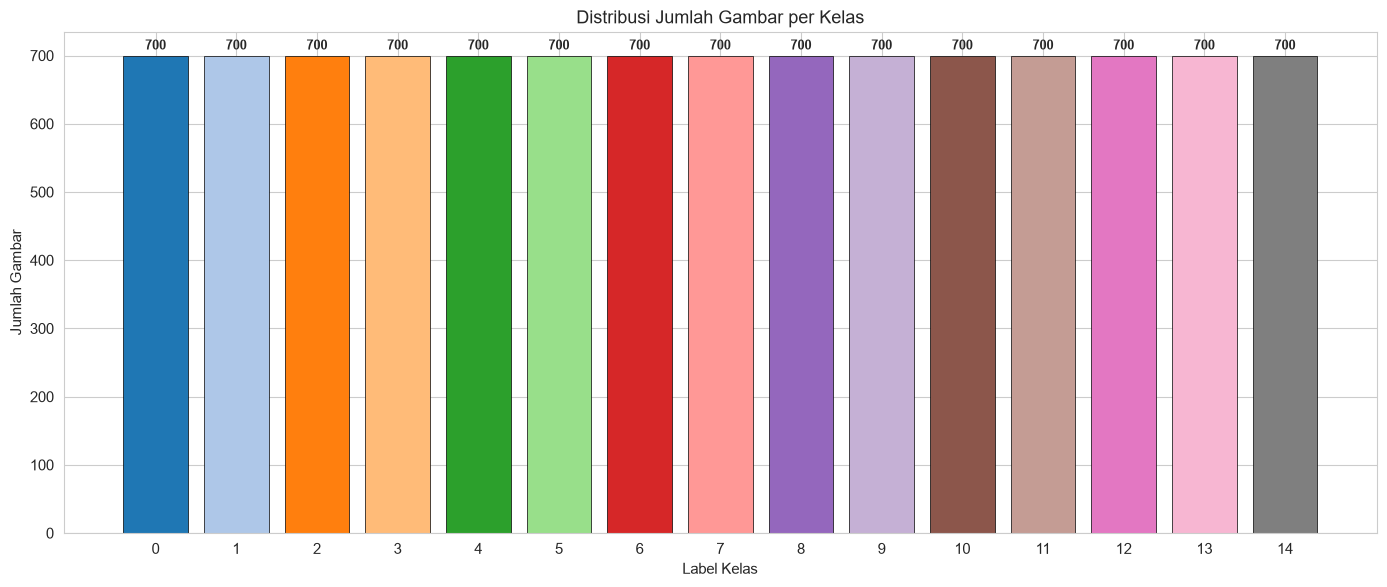

Grafik disimpan ke outputs/figures/distribusi_kelas.png


In [9]:
# Visualisasi distribusi kelas
fig, ax = plt.subplots(figsize=(14, 6))
colors = [plt.cm.tab20(i) for i in range(NUM_CLASSES)]
bars = ax.bar(list(range(NUM_CLASSES)), class_counts.tolist(), color=colors, edgecolor='black', linewidth=0.5)

# Label di atas bar
for bar, count in zip(bars, class_counts.tolist()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, str(count),
            ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xlabel('Label Kelas')
ax.set_ylabel('Jumlah Gambar')
ax.set_title('Distribusi Jumlah Gambar per Kelas')
ax.set_xticks(range(NUM_CLASSES))
ax.set_xticklabels([str(i) for i in range(NUM_CLASSES)])

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'distribusi_kelas.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan ke outputs/figures/distribusi_kelas.png")

## 6. Distribusi Jumlah Gambar per Writer ID

Ini penting karena kita akan membagi data berdasarkan `writer_id` untuk validasi.

In [10]:
writer_counts = df_labels['writer_id'].value_counts().sort_index()
print(f"Jumlah writer unik: {len(writer_counts)}")
print(f"Gambar per writer — Min: {writer_counts.min()} | Max: {writer_counts.max()} | Rata-rata: {writer_counts.mean():.1f}")
print()

# Statistik ringkas
print("Statistik distribusi writer:")
print(writer_counts.describe())

Jumlah writer unik: 70
Gambar per writer — Min: 150 | Max: 150 | Rata-rata: 150.0

Statistik distribusi writer:
count     70.0
mean     150.0
std        0.0
min      150.0
25%      150.0
50%      150.0
75%      150.0
max      150.0
Name: count, dtype: float64


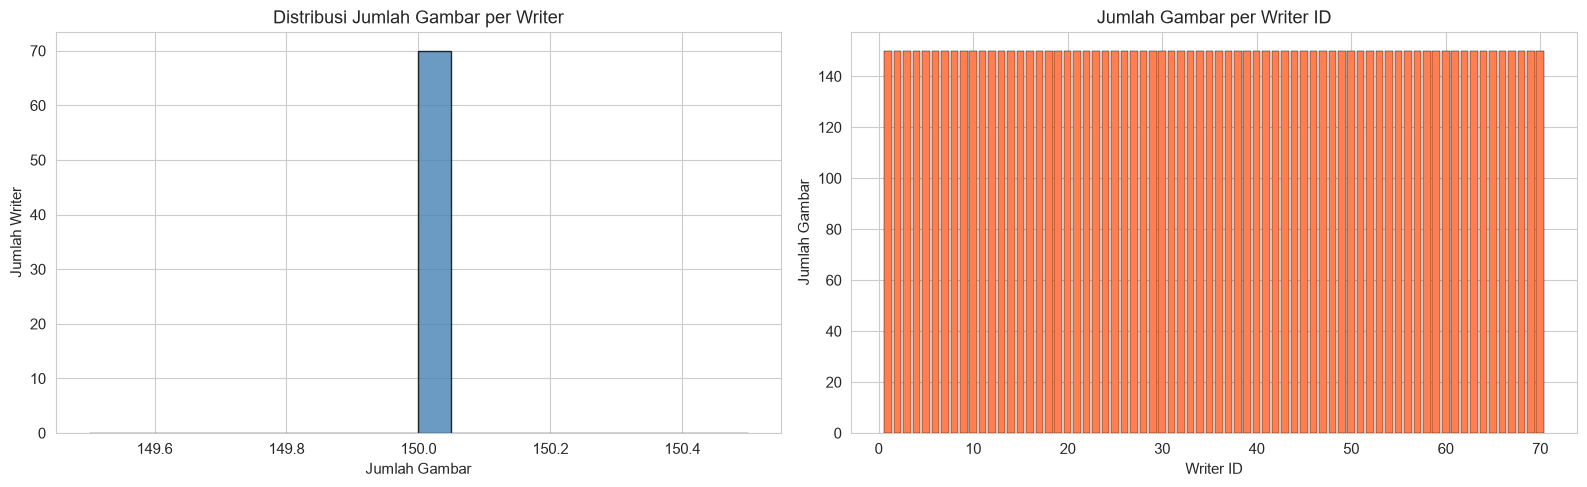

Grafik disimpan ke outputs/figures/distribusi_writer.png


In [11]:
# Visualisasi distribusi writer
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histogram jumlah gambar per writer
axes[0].hist(writer_counts.tolist(), bins=20, color='steelblue', edgecolor='black', alpha=0.8)
axes[0].set_xlabel('Jumlah Gambar')
axes[0].set_ylabel('Jumlah Writer')
axes[0].set_title('Distribusi Jumlah Gambar per Writer')

# Bar chart per writer_id
axes[1].bar(writer_counts.index.tolist(), writer_counts.tolist(), color='coral', edgecolor='black', linewidth=0.3)
axes[1].set_xlabel('Writer ID')
axes[1].set_ylabel('Jumlah Gambar')
axes[1].set_title('Jumlah Gambar per Writer ID')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'distribusi_writer.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan ke outputs/figures/distribusi_writer.png")

In [12]:
# Cek berapa kelas yang ditulis oleh setiap writer
writer_class_coverage = df_labels.groupby('writer_id')['label'].nunique()
print("Jumlah kelas yang ditulis per writer:")
print(writer_class_coverage.value_counts().sort_index())
print()

writers_all_classes = (writer_class_coverage == NUM_CLASSES).sum()
print(f"Writer yang menulis semua {NUM_CLASSES} kelas: {writers_all_classes}/{len(writer_class_coverage)}")

Jumlah kelas yang ditulis per writer:
label
15    70
Name: count, dtype: int64

Writer yang menulis semua 15 kelas: 70/70


## 7. Contoh Gambar untuk Setiap Kelas

C:\Users\TUF\AppData\Local\Temp\ipykernel_1404\902099746.py:28: UserWarning: Glyph 38646 (\N{CJK UNIFIED IDEOGRAPH-96F6}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\TUF\AppData\Local\Temp\ipykernel_1404\902099746.py:28: UserWarning: Glyph 19968 (\N{CJK UNIFIED IDEOGRAPH-4E00}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\TUF\AppData\Local\Temp\ipykernel_1404\902099746.py:28: UserWarning: Glyph 20108 (\N{CJK UNIFIED IDEOGRAPH-4E8C}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\TUF\AppData\Local\Temp\ipykernel_1404\902099746.py:28: UserWarning: Glyph 19977 (\N{CJK UNIFIED IDEOGRAPH-4E09}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\TUF\AppData\Local\Temp\ipykernel_1404\902099746.py:28: UserWarning: Glyph 22235 (\N{CJK UNIFIED IDEOGRAPH-56DB}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\TUF\AppData\Local\Temp\ipykernel_1404\902099746.py:28: UserWarning: Glyph 20116 (\N{CJK UNIFIED IDEOGRAPH-4E94}) missing from font(s) Ar

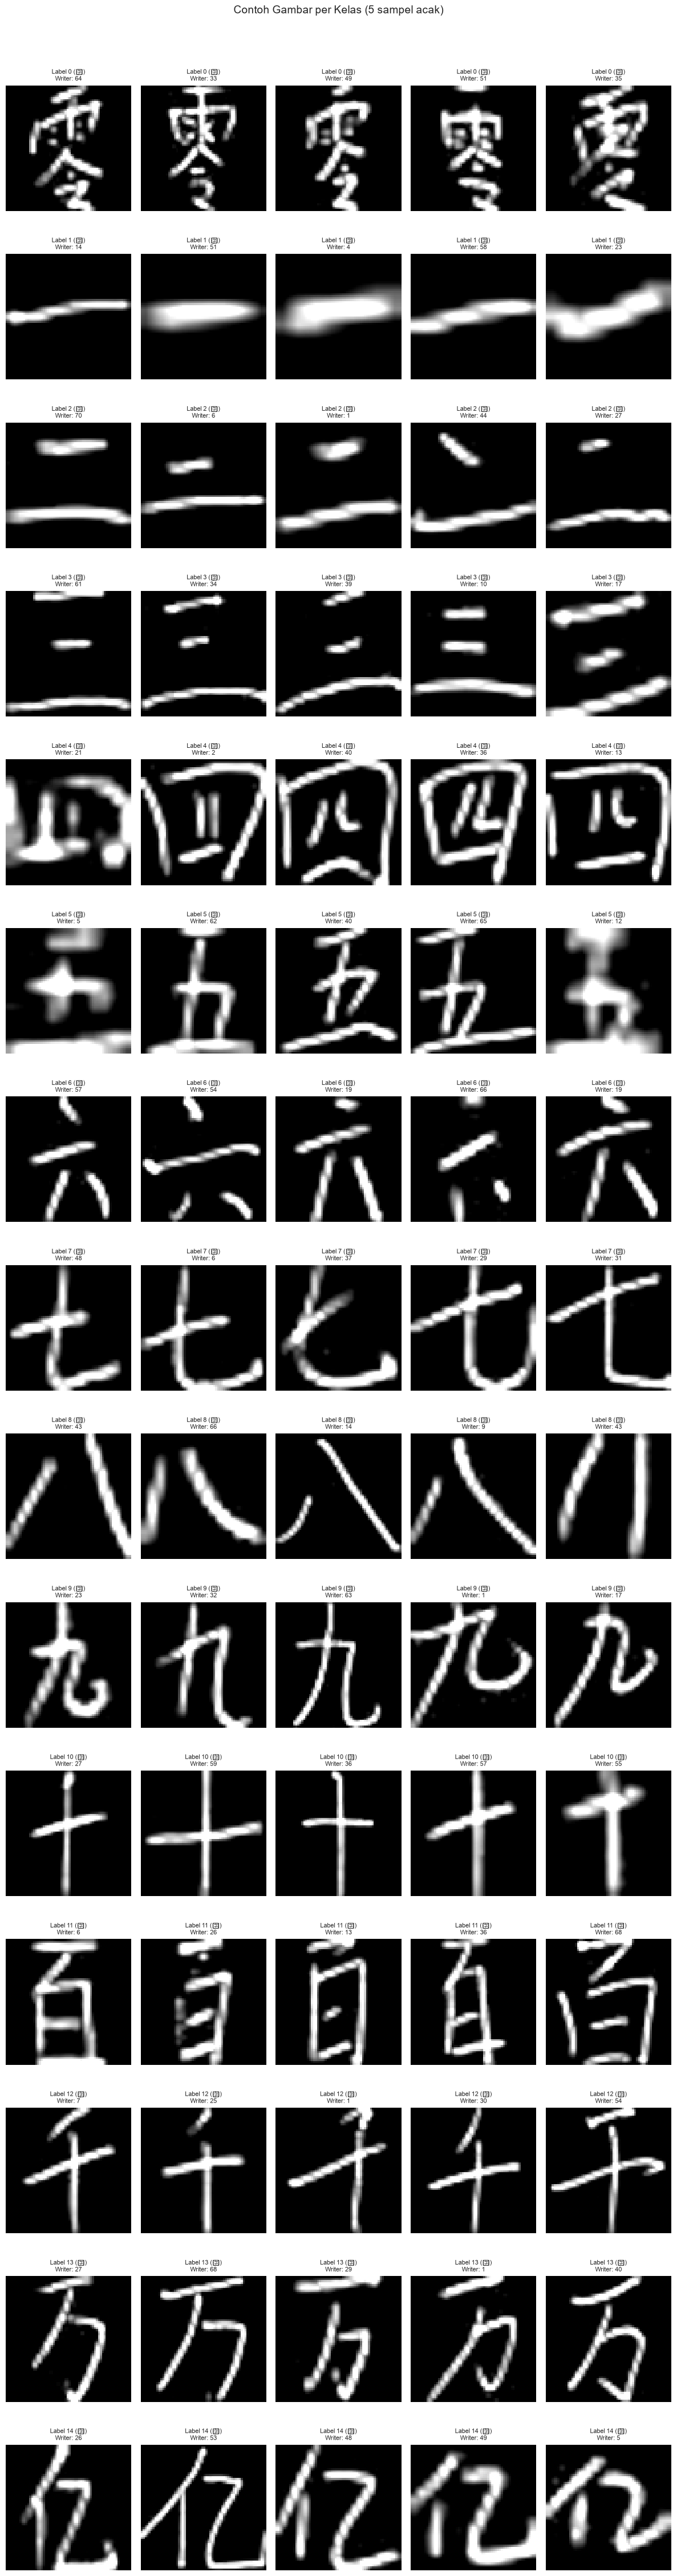

Grafik disimpan ke outputs/figures/contoh_gambar_per_kelas.png


In [13]:
# Tampilkan 5 contoh gambar untuk setiap kelas
n_examples = 5

fig, axes = plt.subplots(NUM_CLASSES, n_examples, figsize=(12, 3 * NUM_CLASSES))

for label_idx in range(NUM_CLASSES):
    # Ambil beberapa sampel dari kelas ini
    samples = df_labels[df_labels['label'] == label_idx].sample(
        n=min(n_examples, len(df_labels[df_labels['label'] == label_idx])),
        random_state=42
    )
    
    for col_idx, (_, row) in enumerate(samples.iterrows()):
        img_path = os.path.join(TRAIN_IMG_DIR, f"{row['id']}.png")
        img = load_single_image(img_path)
        
        ax = axes[label_idx, col_idx] if NUM_CLASSES > 1 else axes[col_idx]
        if img is not None:
            ax.imshow(img, cmap='gray')
        ax.set_title(f"Label {label_idx} ({label_to_char.get(label_idx, '?')})\nWriter: {row['writer_id']}", fontsize=8)
        ax.axis('off')
    
    # Kosongkan kolom sisa jika sampel kurang dari n_examples
    for col_idx in range(len(samples), n_examples):
        axes[label_idx, col_idx].axis('off')

plt.suptitle('Contoh Gambar per Kelas (5 sampel acak)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'contoh_gambar_per_kelas.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan ke outputs/figures/contoh_gambar_per_kelas.png")

## 8. Contoh Gambar dari Writer yang Berbeda

Untuk melihat variasi gaya tulisan antar writer.

C:\Users\TUF\AppData\Local\Temp\ipykernel_1404\3401706208.py:27: UserWarning: Glyph 38646 (\N{CJK UNIFIED IDEOGRAPH-96F6}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\TUF\AppData\Local\Temp\ipykernel_1404\3401706208.py:28: UserWarning: Glyph 38646 (\N{CJK UNIFIED IDEOGRAPH-96F6}) missing from font(s) Arial.
  plt.savefig(os.path.join(FIGURES_DIR, 'variasi_writer.png'), dpi=150, bbox_inches='tight')
c:\Users\TUF\OneDrive\Semester 5\ADM\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 38646 (\N{CJK UNIFIED IDEOGRAPH-96F6}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


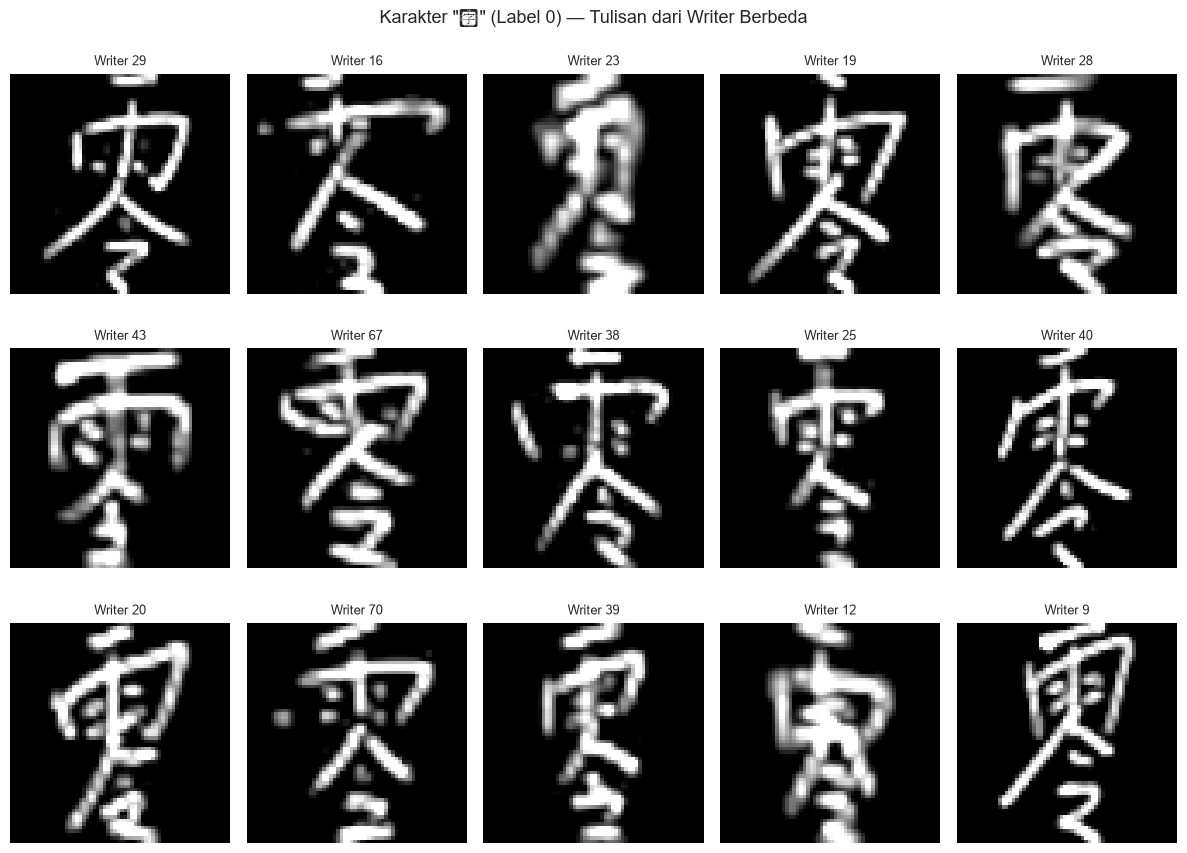

Grafik disimpan ke outputs/figures/variasi_writer.png


In [14]:
# Pilih satu kelas (misal label 0 = 零) dan tampilkan tulisan dari writer berbeda
target_label = 0
char_name = label_to_char.get(target_label, '?')

samples_by_writer = df_labels[df_labels['label'] == target_label].drop_duplicates('writer_id')
samples_by_writer = samples_by_writer.head(15)  # Ambil 15 writer

n_show = len(samples_by_writer)
cols = 5
rows = (n_show + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
axes = axes.flatten() if rows > 1 else [axes] if cols == 1 else axes.flatten()

for idx, (_, row) in enumerate(samples_by_writer.iterrows()):
    img_path = os.path.join(TRAIN_IMG_DIR, f"{row['id']}.png")
    img = load_single_image(img_path)
    if img is not None:
        axes[idx].imshow(img, cmap='gray')
    axes[idx].set_title(f"Writer {row['writer_id']}", fontsize=9)
    axes[idx].axis('off')

for idx in range(n_show, len(axes)):
    axes[idx].axis('off')

plt.suptitle(f'Karakter "{char_name}" (Label {target_label}) — Tulisan dari Writer Berbeda', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'variasi_writer.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan ke outputs/figures/variasi_writer.png")

## 9. Pemeriksaan Properti Gambar

Cek ukuran gambar, jumlah channel, rentang nilai piksel, dan gambar rusak.

In [15]:
# Periksa properti seluruh gambar
widths = []
heights = []
channels = []
pixel_mins = []
pixel_maxs = []
pixel_means = []
corrupted = []

for _, row in df_labels.iterrows():
    img_path = os.path.join(TRAIN_IMG_DIR, f"{row['id']}.png")
    try:
        with Image.open(img_path) as img_pil:
            w, h = img_pil.size
            mode = img_pil.mode
            widths.append(w)
            heights.append(h)
            
            # Jumlah channel berdasarkan mode
            ch_map = {'L': 1, 'RGB': 3, 'RGBA': 4, 'P': 1}
            channels.append(ch_map.get(mode, -1))
            
            arr = np.array(img_pil)
            pixel_mins.append(arr.min())
            pixel_maxs.append(arr.max())
            pixel_means.append(arr.mean())
    except Exception as e:
        corrupted.append((row['id'], str(e)))

print(f"Gambar berhasil dibaca: {len(widths)}")
print(f"Gambar rusak/gagal: {len(corrupted)}")
if corrupted:
    for cid, cerr in corrupted[:10]:
        print(f"  - {cid}: {cerr}")

print(f"\nUkuran gambar:")
print(f"  Width  — Min: {min(widths)}, Max: {max(widths)}, Unik: {set(widths)}")
print(f"  Height — Min: {min(heights)}, Max: {max(heights)}, Unik: {set(heights)}")
print(f"  Channel — Unik: {set(channels)}")

print(f"\nNilai piksel:")
print(f"  Min piksel: {min(pixel_mins)}")
print(f"  Max piksel: {max(pixel_maxs)}")
print(f"  Rata-rata piksel keseluruhan: {np.mean(pixel_means):.2f}")

Gambar berhasil dibaca: 10500
Gambar rusak/gagal: 0

Ukuran gambar:
  Width  — Min: 64, Max: 64, Unik: {64}
  Height — Min: 64, Max: 64, Unik: {64}
  Channel — Unik: {1}

Nilai piksel:
  Min piksel: 0
  Max piksel: 255
  Rata-rata piksel keseluruhan: 39.14


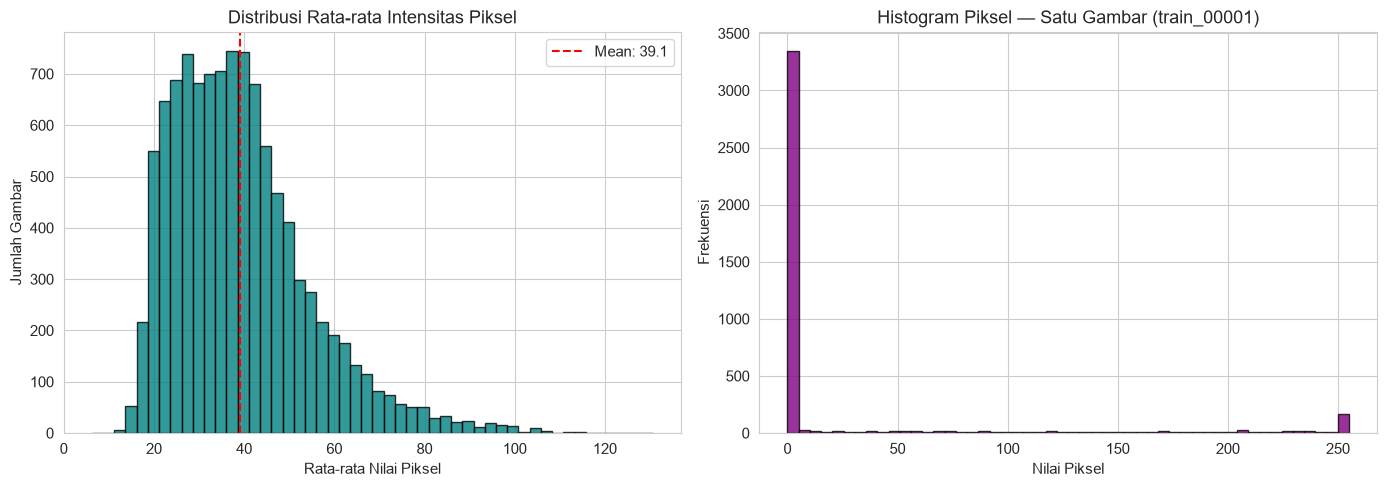

Grafik disimpan ke outputs/figures/distribusi_piksel.png


In [16]:
# Distribusi rata-rata nilai piksel per gambar
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(pixel_means, bins=50, color='teal', edgecolor='black', alpha=0.8)
axes[0].set_xlabel('Rata-rata Nilai Piksel')
axes[0].set_ylabel('Jumlah Gambar')
axes[0].set_title('Distribusi Rata-rata Intensitas Piksel')
axes[0].axvline(np.mean(pixel_means), color='red', linestyle='--', label=f'Mean: {np.mean(pixel_means):.1f}')
axes[0].legend()

# Contoh histogram piksel dari satu gambar
sample_img_path = os.path.join(TRAIN_IMG_DIR, f"{df_labels.iloc[0]['id']}.png")
sample_img = load_single_image(sample_img_path)
if sample_img is not None:
    axes[1].hist(sample_img.flatten(), bins=50, color='purple', edgecolor='black', alpha=0.8)
    axes[1].set_xlabel('Nilai Piksel')
    axes[1].set_ylabel('Frekuensi')
    axes[1].set_title(f'Histogram Piksel — Satu Gambar ({df_labels.iloc[0]["id"]})')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'distribusi_piksel.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan ke outputs/figures/distribusi_piksel.png")

## 10. Ringkasan Temuan EDA

**Catatan:** Interpretasi di bawah ini akan diperbarui setelah notebook dijalankan berdasarkan hasil aktual.

In [17]:
# Ringkasan otomatis berdasarkan hasil pemeriksaan di atas
print("RINGKASAN EDA")

print(f"Jumlah total gambar: {len(df_labels)}")
print(f"Jumlah kelas: {len(unique_labels)}")
print(f"Jumlah writer unik: {df_labels['writer_id'].nunique()}")
print(f"Gambar rusak: {len(corrupted)}")
print(f"ID duplikat: {dup_count}")
print(f"Missing values: {df_labels.isnull().sum().sum()}")
print(f"Ukuran gambar: {set(widths)} x {set(heights)} piksel")
print(f"Jumlah channel: {set(channels)}")
print(f"Rentang piksel: [{min(pixel_mins)}, {max(pixel_maxs)}]")
print(f"Distribusi kelas — Min: {class_counts.min()}, Max: {class_counts.max()}")


if class_counts.max() / class_counts.min() > 2:
    print(" Dataset TIDAK seimbang — rasio kelas terbesar/terkecil > 2")
else:
    print(" Dataset cukup seimbang")

print("\n EDA selesai. Lanjut ke notebook 02_training.ipynb")

RINGKASAN EDA
Jumlah total gambar: 10500
Jumlah kelas: 15
Jumlah writer unik: 70
Gambar rusak: 0
ID duplikat: 0
Missing values: 0
Ukuran gambar: {64} x {64} piksel
Jumlah channel: {1}
Rentang piksel: [0, 255]
Distribusi kelas — Min: 700, Max: 700
 Dataset cukup seimbang

 EDA selesai. Lanjut ke notebook 02_training.ipynb
